# California Housing Price Prediction: OLS vs Ridge vs Lasso

**Goal:** Predict median house values and compare OLS, Ridge (L2), and Lasso (L1) regression using RMSE, MAE, and R².

This notebook covers data loading, missing-value imputation, engineered features, correlation heatmap, 80/20 split, numeric scaling, categorical encoding, GridSearchCV, predicted-vs-actual plots, and residual plots. Run cells from top to bottom. Internet access is needed to load the CSV.

## 1. Import libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load dataset

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(DATA_URL)
print("Dataset shape:", df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


,missing_values
total_bedrooms,207
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


## 3. Feature engineering

In [ ]:
def add_features(data):
    data = data.copy()
    data["rooms_per_household"] = data["total_rooms"] / data["households"].replace(0, np.nan)
    data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"].replace(0, np.nan)
    data["population_per_household"] = data["population"] / data["households"].replace(0, np.nan)
    data["income_x_rooms"] = data["median_income"] * data["rooms_per_household"]
    return data

df_features = add_features(df)
display(df_features.head())
display(df_features.describe().T)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,58.144254
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,51.785271
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,60.150315
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,32.827897
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,24.161264


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
housing_median_age,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
total_rooms,20640.0,2635.763081,2181.615252,2.000000,1447.750000,2127.000000,3148.000000,39320.000000
total_bedrooms,20433.0,537.870553,421.385070,1.000000,296.000000,435.000000,647.000000,6445.000000
population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
households,20640.0,499.539680,382.329753,1.000000,280.000000,409.000000,605.000000,6082.000000
median_income,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
median_house_value,20640.0,206855.816909,115395.615874,14999.000000,119600.000000,179700.000000,264725.000000,500001.000000
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091


## 4. Correlation heatmap and multicollinearity

The heatmap helps identify highly correlated numeric features. Ridge and Lasso regularization later help control unstable coefficients caused by multicollinearity. Correlation does not prove causation.

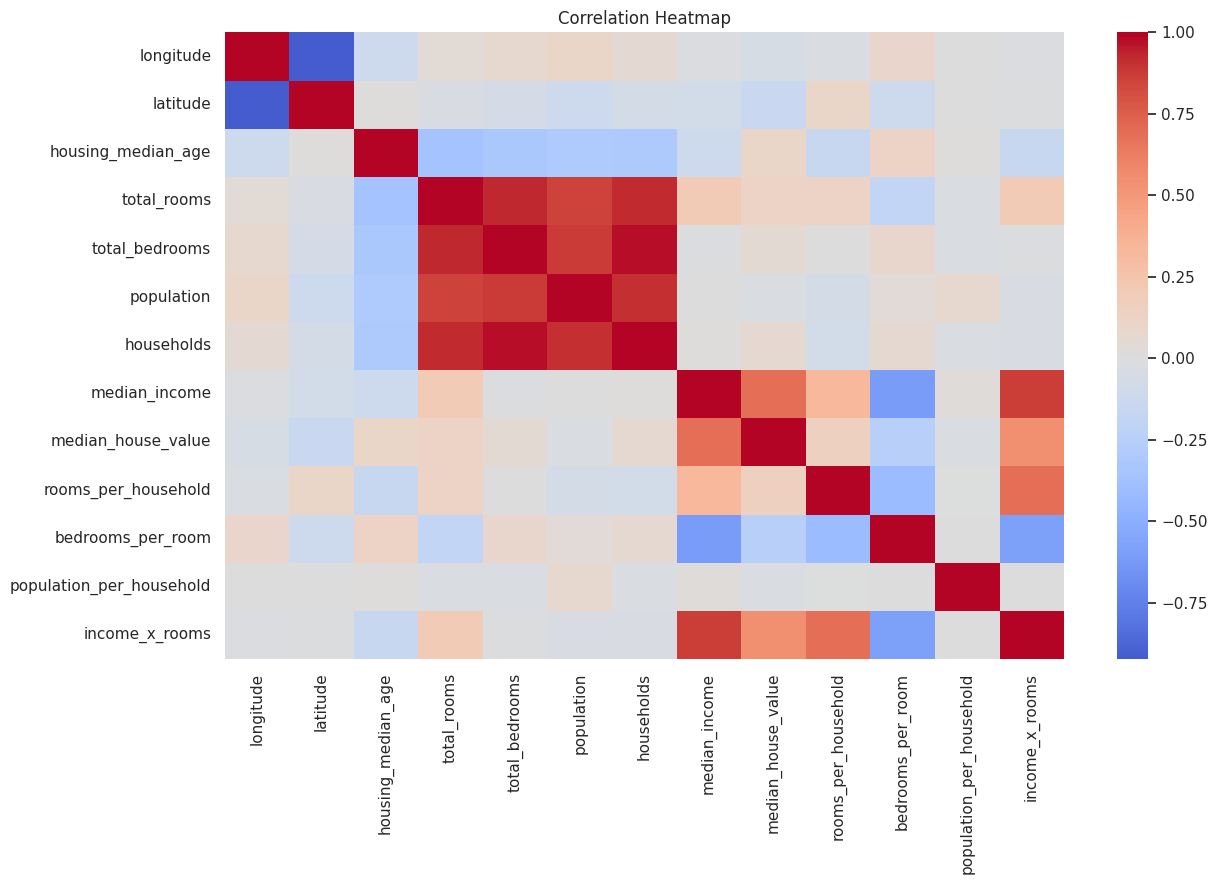

,correlation_with_target
bedrooms_per_room,-0.254632
latitude,-0.144160
longitude,-0.045967
population,-0.024650
population_per_household,-0.023737
total_bedrooms,0.049457
households,0.065843
housing_median_age,0.105623
total_rooms,0.134153
rooms_per_household,0.151948


In [ ]:
numeric_corr = df_features.select_dtypes(include=np.number).copy()
numeric_corr = numeric_corr.fillna(numeric_corr.median(numeric_only=True))
plt.figure(figsize=(13, 9))
sns.heatmap(numeric_corr.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
display(numeric_corr.corr()["median_house_value"].drop("median_house_value").sort_values().to_frame("correlation_with_target"))

## 5. Split features and target (80/20)

In [ ]:
X = df_features.drop(columns=["median_house_value"])
y = df_features["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 16512 | Testing rows: 4128


## 6. Preprocessing: impute, scale, and encode

In [ ]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms']
Categorical features: ['ocean_proximity']


## 7. Train OLS, Ridge and Lasso; tune alpha with GridSearchCV

In [ ]:
ols = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])
ols.fit(X_train, y_train)

ridge = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])
ridge_search = GridSearchCV(
    ridge, {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_search.fit(X_train, y_train)

lasso = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=20000))
])
lasso_search = GridSearchCV(
    lasso, {"model__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)
lasso_search.fit(X_train, y_train)

models = {
    "OLS": ols,
    "Ridge (tuned)": ridge_search.best_estimator_,
    "Lasso (tuned)": lasso_search.best_estimator_
}
print("Best Ridge parameters:", ridge_search.best_params_)
print("Best Lasso parameters:", lasso_search.best_params_)

Best Ridge parameters: {'model__alpha': 1.0}
Best Lasso parameters: {'model__alpha': 1.0}


## 8. Compare test-set metrics

In [ ]:
results = []
predictions = {}
for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(3))

,Model,RMSE,MAE,R2
0,OLS,68917.317,49709.540,0.638
1,Lasso (tuned),68918.676,49710.272,0.638
2,Ridge (tuned),68925.957,49715.841,0.637


## 9. Predicted vs actual plots

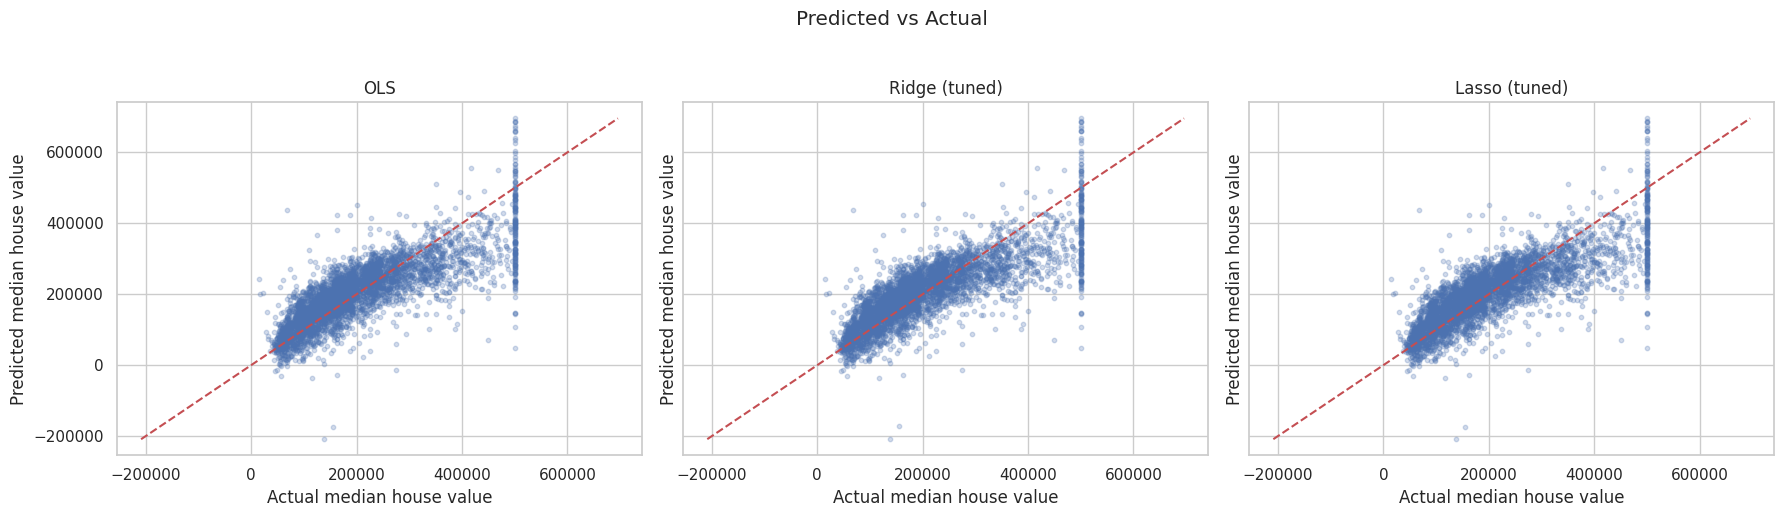

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.25, s=10)
    lo = min(float(y_test.min()), float(np.min(pred)))
    hi = max(float(y_test.max()), float(np.max(pred)))
    ax.plot([lo, hi], [lo, hi], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual median house value")
    ax.set_ylabel("Predicted median house value")
fig.suptitle("Predicted vs Actual", y=1.03)
plt.tight_layout()
plt.show()

## 10. Residual distribution curves

Residual = actual value − predicted value. Residuals centered around zero are generally desirable; use this plot together with the other evaluation metrics.

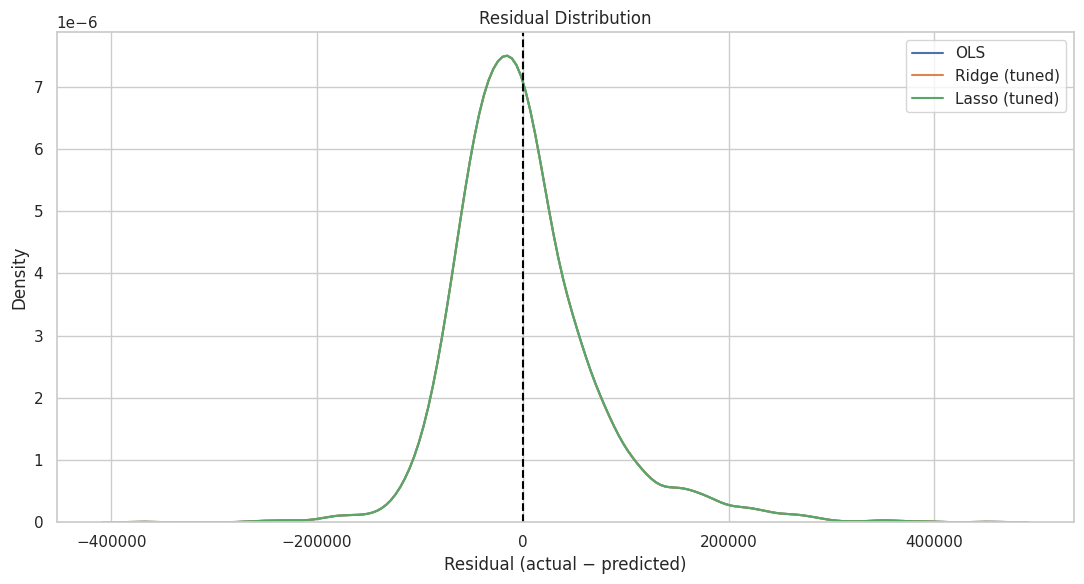

In [ ]:
plt.figure(figsize=(11, 6))
for name, pred in predictions.items():
    residuals = y_test.to_numpy() - pred
    sns.kdeplot(residuals, label=name)
plt.axvline(0, color="black", linestyle="--")
plt.title("Residual Distribution")
plt.xlabel("Residual (actual − predicted)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Residuals vs predicted values

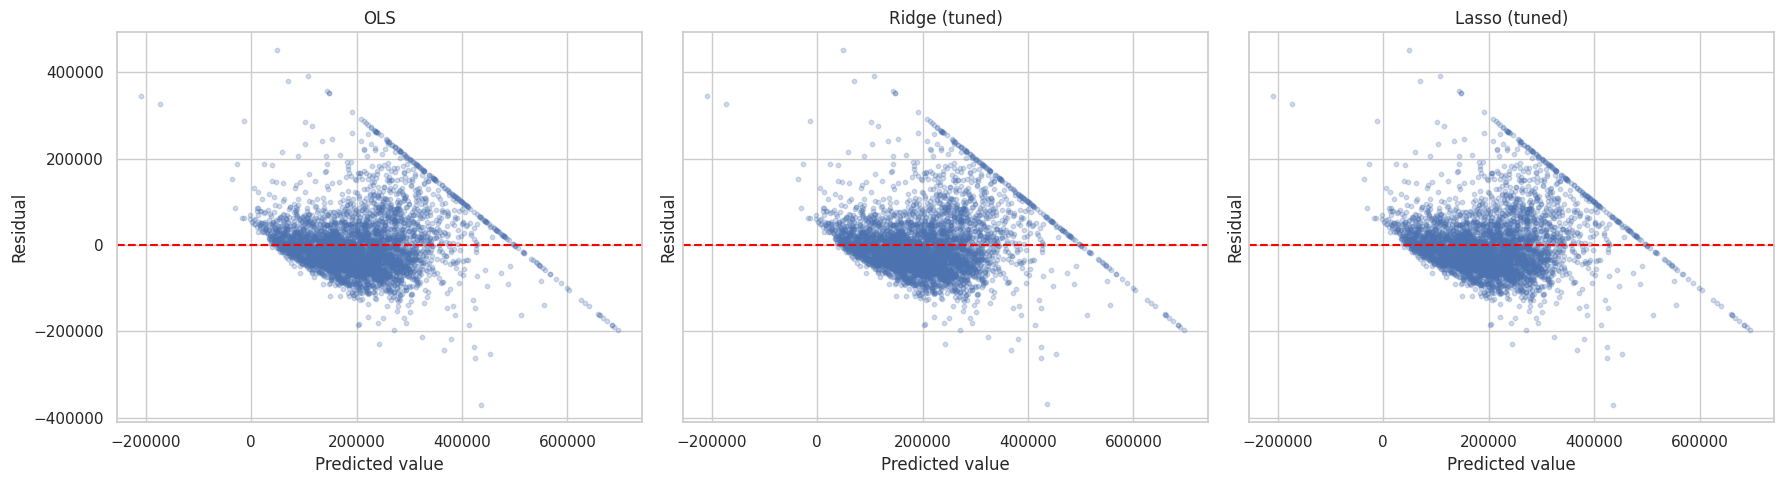

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (name, pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - pred
    ax.scatter(pred, residuals, alpha=0.25, s=10)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Residual")
plt.tight_layout()
plt.show()

## 12. Conclusion

In [ ]:
best = results_df.iloc[0]
print("Lowest test RMSE model:", best["Model"])
print(f"RMSE: {best['RMSE']:.2f}")
print(f"MAE: {best['MAE']:.2f}")
print(f"R²: {best['R2']:.4f}")
display(results_df.round(3))
print("Lower RMSE/MAE means smaller errors; higher R² means more target variation is explained.")

Lowest test RMSE model: OLS
RMSE: 68917.32
MAE: 49709.54
R²: 0.6375


,Model,RMSE,MAE,R2
0,OLS,68917.317,49709.540,0.638
1,Lasso (tuned),68918.676,49710.272,0.638
2,Ridge (tuned),68925.957,49715.841,0.637


Lower RMSE/MAE means smaller errors; higher R² means more target variation is explained.


## Notes
- Numeric missing values are imputed with the median; categorical missing values with the most frequent category.
- Numeric features are standardized and `ocean_proximity` is one-hot encoded.
- Ratio/interaction-style features are included.
- Ridge and Lasso alpha values are selected using 5-fold GridSearchCV.
- Only report metric values in your README after running the notebook and checking its results.